In [1]:
"""
1. Create a straight line dataset using the linear regression formula (weight * X + bias).
Set weight=0.3 and bias=0.9 there should be at least 100 datapoints total.
Split the data into 80% training, 20% testing.
Plot the training and testing data so it becomes visual.

2. Build a PyTorch model by subclassing nn.Module.
Inside should be a randomly initialized nn.Parameter() with requires_grad=True, one for weights and one for bias.
Implement the forward() method to compute the linear regression function you used to create the dataset in 1.
Once you've constructed the model, make an instance of it and check its state_dict().
Note: If you'd like to use nn.Linear() instead of nn.Parameter() you can.
"""

"\n1. Create a straight line dataset using the linear regression formula (weight * X + bias).\nSet weight=0.3 and bias=0.9 there should be at least 100 datapoints total.\nSplit the data into 80% training, 20% testing.\nPlot the training and testing data so it becomes visual.\n\n2. Build a PyTorch model by subclassing nn.Module.\nInside should be a randomly initialized nn.Parameter() with requires_grad=True, one for weights and one for bias.\nImplement the forward() method to compute the linear regression function you used to create the dataset in 1.\nOnce you've constructed the model, make an instance of it and check its state_dict().\nNote: If you'd like to use nn.Linear() instead of nn.Parameter() you can.\n"

In [2]:
import torch
import matplotlib.pyplot as plt

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [4]:
# Create the dataset
w = 0.3
b = 0.9

a = 0
e = 1
step = 0.01

y = 0
x = 0

x = torch.arange(a, e, step).unsqueeze(dim=1)   # here I forgot to unsqueeze() '.unsqueeze(dim=1)'
print(x[:10])
print(" ")

y = x*w + b
print(y[:10])

print(len(x))
print(len(y))


tensor([[0.0000],
        [0.0100],
        [0.0200],
        [0.0300],
        [0.0400],
        [0.0500],
        [0.0600],
        [0.0700],
        [0.0800],
        [0.0900]])
 
tensor([[0.9000],
        [0.9030],
        [0.9060],
        [0.9090],
        [0.9120],
        [0.9150],
        [0.9180],
        [0.9210],
        [0.9240],
        [0.9270]])
100
100


In [5]:
# Split the dataset

test_train_split = int(len(x) * 0.8)
print(test_train_split)

train_x = x[:test_train_split]
train_y = y[:test_train_split]

test_x = x[test_train_split:]
test_y = y[test_train_split:]


print(len(train_x), len(train_y), len(test_x),len(test_y))

80
80 80 20 20


In [19]:

def plot_dataset(
                test_x=test_x,
                test_y=test_y,
                train_x=train_x,
                train_y=train_y,
                predictions=None,
                title="Dataset"):

  plt.figure(figsize=(10, 7))
  plt.scatter(train_x, train_y, label="Train", c="b", s=4)    # here I forgot 'c' and 's' for colour and size
  plt.scatter(test_x, test_y, label="Test", c="r", s=4)
  plt.legend()
  plt.title(title)
  plt.show()

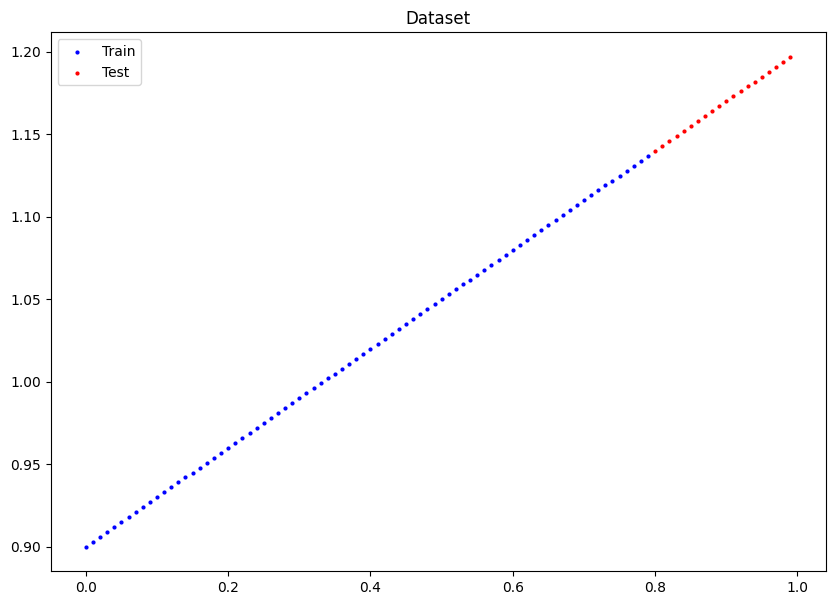

In [7]:
plot_dataset(test_x, test_y, train_x, train_y)

In [8]:
from torch import nn
class LinearRegression(nn.Module):          # standart initialization
  def __init__(self):
    super().__init__()

    self.weights = nn.Parameter(torch.randn(                    # can be functionized see below
                                            1,
                                            requires_grad=True,
                                            dtype=torch.float))
    self.biais = nn.Parameter(torch.randn(
                                            1,
                                            requires_grad=True,
                                            dtype=torch.float))

  def forward(self, x):
    return self.weights * x + self.biais

  # ## Option 2
# class LinearRegressionModel(nn.Module):
#   def __init__(self):
#     super().__init__()
#     self.linear_layer = nn.Linear(in_features = 1,
#                                   out_features = 1)
#   def forward(self,x : torch.Tensor) -> torch.Tensor:
#     return self.linear_layer(x)

In [9]:
torch.manual_seed(42)
model_1= LinearRegression()
list(model_1.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [10]:
print(model_1.state_dict())
print(w, b)

OrderedDict({'weights': tensor([0.3367]), 'biais': tensor([0.1288])})
0.3 0.9


In [11]:
y_preds = model_1(train_x)
y_preds[:10]

tensor([[0.1288],
        [0.1322],
        [0.1355],
        [0.1389],
        [0.1423],
        [0.1456],
        [0.1490],
        [0.1524],
        [0.1557],
        [0.1591]], grad_fn=<SliceBackward0>)

In [12]:
device = next(model_1.parameters()).device
device

device(type='cpu')

In [13]:
loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)


In [14]:
# Set the hyperparameters
torch.manual_seed(42)
EPOCHS = 600

# Send data to device

train_x = train_x.to(device)
train_y = train_y.to(device)
test_x = test_x.to(device)
test_y = test_y.to(device)

# Set the loop

for epoch in range(EPOCHS):
  model_1.train()             # put model in train mode
  y_pred = model_1(train_x)   # forward pass
  loss = loss_fn(y_pred, train_y)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


  # Test every 10
  if epoch % 10 == 0:
    model_1.eval()

    with torch.inference_mode():
      y_pred = model_1(test_x)
      test_loss = loss_fn(y_pred, test_y)
      print(f"Epoch: {epoch} | Train loss: {loss} | Test loss: {test_loss}")


Epoch: 0 | Train loss: 0.7566978335380554 | Test loss: 0.7248174548149109
Epoch: 10 | Train loss: 0.6410952806472778 | Test loss: 0.5894648432731628
Epoch: 20 | Train loss: 0.5254928469657898 | Test loss: 0.4541124403476715
Epoch: 30 | Train loss: 0.40989047288894653 | Test loss: 0.31876006722450256
Epoch: 40 | Train loss: 0.2942880392074585 | Test loss: 0.18340764939785004
Epoch: 50 | Train loss: 0.17868563532829285 | Test loss: 0.04805523157119751
Epoch: 60 | Train loss: 0.07658576965332031 | Test loss: 0.07274086028337479
Epoch: 70 | Train loss: 0.05743539333343506 | Test loss: 0.11017072200775146
Epoch: 80 | Train loss: 0.05255373567342758 | Test loss: 0.11581540107727051
Epoch: 90 | Train loss: 0.04897591844201088 | Test loss: 0.11232650279998779
Epoch: 100 | Train loss: 0.045542728155851364 | Test loss: 0.10467890650033951
Epoch: 110 | Train loss: 0.0421157106757164 | Test loss: 0.09703131765127182
Epoch: 120 | Train loss: 0.03868866711854935 | Test loss: 0.08938358724117279
Epoc

In [15]:
print(model_1.state_dict())

OrderedDict({'weights': tensor([0.3067]), 'biais': tensor([0.9011])})


In [16]:
model_1.eval()

with torch.inference_mode():

  y_pred = model_1(test_x)
  test_loss = loss_fn(y_pred, test_y)
  print(f"Test loss: {test_loss}")
  print(y_pred)

Test loss: 0.007045787759125233
tensor([[1.1464],
        [1.1495],
        [1.1525],
        [1.1556],
        [1.1587],
        [1.1617],
        [1.1648],
        [1.1679],
        [1.1709],
        [1.1740],
        [1.1771],
        [1.1801],
        [1.1832],
        [1.1863],
        [1.1893],
        [1.1924],
        [1.1955],
        [1.1985],
        [1.2016],
        [1.2047]])


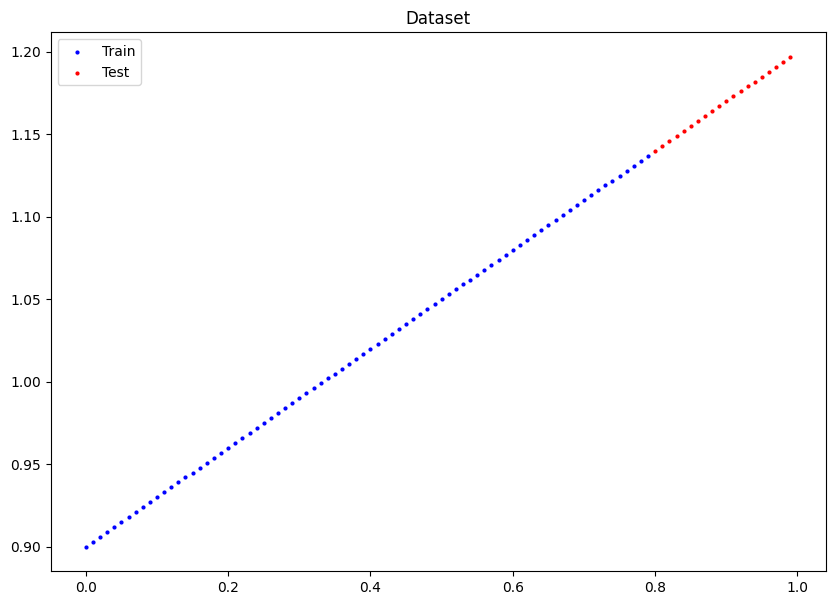

In [20]:
plot_dataset(predictions=y_pred)

In [26]:
# Save the model

from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents = True,exist_ok = True)        # Now the folder is created on disk. parents=True creates any missing parent folders along the way; exist_ok=True means "don't raise an error if it's already there", so re-running the cell is safe. This is the line that was missing from your pizza-download cell and caused the FileNotFoundError.
# 2. Create model save path
MODEL_NAME = "01_pytorch_model"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME               # The / operator on a Path joins path components. Gives models/01_pytorch_model. Not division — Path overloads / because it reads like a filesystem path.
# 3. Save the model state dict
print(f"Saving model to {MODEL_SAVE_PATH}")
torch.save(obj = model_1.state_dict(),f = MODEL_SAVE_PATH)

# Create new instance of model and load saved state dict (make sure to put it on the target device)
loaded_model = LinearRegression()                       # Builds a brand new model from your class — with fresh random parameters, nothing to do with model_1. This is the empty vessel.
loaded_model.load_state_dict(torch.load(f = MODEL_SAVE_PATH))
loaded_model.to(device)

# Make predictions with loaded model and compare them to the previous
y_preds_new = loaded_model(test_x)
y_pred == y_preds_new


Saving model to models/01_pytorch_model


tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

In [27]:
loaded_model.state_dict()

OrderedDict([('weights', tensor([0.3067])), ('biais', tensor([0.9011]))])

In [28]:
"""
this wouwld put it on my mac :
from google.colab import files
files.download("models/01_pytorch_model")
"""

'\nthis wouwld put it on my mac : \nfrom google.colab import files\nfiles.download("models/01_pytorch_model")\n'